> Notebook-friendly copy of `part-I/1.5-pandas-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import pandas as `pd` and numpy as `np`, seed any randomness with `default_rng`, and keep units in your column names.

## Exercise 1: Earthquake data analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/usgs-2014-south-napa-earthquake.jpg" alt="A dirt track through a vineyard, broken along its length by a continuous ridge of pushed-up soil following the fault trace" width="800">

<em>Surface rupture from the magnitude 6.0 South Napa earthquake of 24 August 2014 — the kind of event a row in this catalog stands for. The continuous "mole track" running parallel to the strike of the fault indicates some east–west compression on top of the <a href="https://www.usgs.gov/faqs/what-fault-and-what-are-different-types">right-lateral faulting</a>; taken near Buhman Road. Photo <a href="https://www.usgs.gov/media/images/2014-south-napa-ca-m6-earthquake-august-24-6">USGS</a>, public domain.</em>


This exercise reviews the `pandas` fundamentals of this subchapter on one real catalog, covering how to

* open csv files
* manipulate dataframe indexes
* parse date columns
* examine basic dataframe statistics
* manipulate text columns and extract values
* plot dataframe contents using
  * bar charts
  * histograms
  * scatter plots

The data is a snapshot of the [USGS Earthquakes Database](https://earthquake.usgs.gov/earthquakes/search/): every event recorded worldwide in 2014, 120 108 rows.

You do not need to download the file yourself. The pre-supplied cell below fetches and caches it with the help of [pooch](https://www.fatiando.org/pooch/latest/) — there is no need to read pooch's documentation unless you want to — and stores the path to the file in the variable `datafile`.

In [19]:
# Pre-supplied: download and cache the earthquake data.
import pooch

datafile = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Beyond this subchapter**

The tools below were not demonstrated in 1.5's lecture. Each question links its documentation where
it is needed; they are collected here so you know when you are being asked to read a new page rather
than to recall one:

- [`nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) — Q5
- [pandas' text data functions](https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html), and [`Series.str.split`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html) in particular — Q6
- [`unique`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html) — Q7
- [`count`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html) and [`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) — Q9

The scatter plot and colorbar in Q11 are the ones from 1.4.6. Everything else the questions ask for
is from this subchapter's lecture: `read_csv` with date-parsed columns, `set_index`, `.head()`,
`.info()`, `.describe()`, boolean filtering, `.index` and `.values`, `kind="bar"`, `kind="hist"`, and
a logarithmic count axis.

**Q1) First, import `numpy`, `pandas` and `matplotlib`, and — optionally — set the display options.**

Hint: display options are documented [at this link](https://pandas.pydata.org/pandas-docs/stable/user_guide/options.html).

In [20]:
#Q1 first try
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns")

ValueError: Must provide an even number of non-keyword arguments

In [ ]:
#Q1 second try
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30)

  ✍ ***Q1 REFLECTIVE COMMENT*** ✍

  I imported the libraries as requested, but then I wrote `pd.set_option("display.max_columns")` and I got an error (`ValueError: Must provide an even number of non-keyword arguments`). That's because I forgot to put the values saying how many columns I want pandas to show.

**Q2) Use pandas' `read_csv` function directly on `datafile` to open it as a `DataFrame`.**

Display the first few rows with `.head()`, and the column names, dtypes and non-null counts with
`.info()`. Check these tutorials if you have doubts about what the two functions do:
[`.head()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html)
and
[`.info()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.info.html?highlight=info#pandas.DataFrame.info).

`.info()` will show you that the two date columns, `time` and `updated`, came in as plain strings
rather than as dates. They were not parsed automatically. What can you do about that?

In [ ]:
#Q2 first try
# Open the file as a pandas DataFrame, then display the first few rows and the DataFrame info
df = pd.read_csv(datafile)
df["time"].dt.year

In [ ]:
#Q2 second try
# Open the file as a pandas DataFrame, then display the first few rows and the DataFrame info
df = pd.read_csv(datafile)
display(df.head())
df.info()

✍ ***Q2 REFLECTIVE COMMENT*** ✍

My first try here was `df["time"].dt.year`, and I got an error (`AttributeError: Can only use .dt accessor with datetimelike values`).
I mistakenly thought that `time` was already considered as a date but pandas was still considering it as a text.

**Q3) Re-read the data in such a way that both date columns are identified as dates and the earthquake ID is used as the index.**

Check with `.head()` and `.info()` that it worked: `time` and `updated` should now be
`datetime64` columns, and `id` should be the index rather than a column.

Hint: the documentation for `read_csv` is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html?highlight=read_csv).

In [ ]:
#Q3 first try
# Re-read the file, then check with head and info that it worked
df = pd.read_csv(datafile, parse_dates=["time", "updated"], index_col="id")
df["id"]

In [ ]:
#Q3 second try
# Re-read the file, then check with head and info that it worked
df = pd.read_csv(datafile, parse_dates=["time", "updated"], index_col = "id")
display(df.head())
df.info()

✍ ***Q3 REFLECTIVE COMMENT*** ✍

I put `index_col="id"` and then since in Q2 I could see `"id"` as a column, I tried `df["id"]` to check it... I got this error: `KeyError: 'id'`. I felt very confused about why it did not work out, but then I could find some clarity on the course's website in Section 1.5.2: the index was not a column anymore, so I had to use `df.index`.

**Q4) Use `describe` to get the basic statistics of all the columns.**

Hint: the documentation of `describe` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html).

In [ ]:
# Use the describe function
df.describe()

✍ ***Q4 REFLECTIVE COMMENT*** ✍

No problems with this question.

**Q5) Use `nlargest` to get the top 20 earthquakes by magnitude.**

Hint: the documentation of `nlargest` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html).

In [ ]:
# Use nlargest
df.nlargest(20, "mag")

✍ ***Q5 REFLECTIVE COMMENT*** ✍

Got it at first try.

**Q6) Extract the state or country using pandas' text data functions, and add it as a new column to the `DataFrame`.**

Examine the column titled `place`: it holds strings like `"26km S of Redoubt Volcano, Alaska"`, so
it carries both the local description and the state or country. Pull the second part out and store
it in a new column called `country`.

Hint 1: the documentation for pandas' text data functions is [here](https://pandas.pydata.org/pandas-docs/stable/text.html).

Hint 2: you will use `.split()` to extract the country names. The documentation of this function
can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html?highlight=split#pandas.Series.str.split).

In [ ]:
#Q6 first try
# Extract the state or country, and add it as a new column to the DataFrame called country
df["country"] = df["place"].split(",")

In [ ]:
#Q6 second try
# Extract the state or country, and add it as a new column to the DataFrame called country
df["country"] = df["place"].str.split(",").str[1]
print(df["country"].unique()[:30])
print("missing values:", df["country"].isna().sum())

In [21]:
#Q6 third try
# Extract the state or country, and add it as a new column to the DataFrame called country
df["country"] = df["place"].str.split(",").str[-1].str.strip()
df[["place", "country"]].head(10)

,place,country
id,,
ak11155107,"26km S of Redoubt Volcano, Alaska",Alaska
nn00436847,"32km S of Alamo, Nevada",Nevada
ak11151142,"12km NNW of North Nenana, Alaska",Alaska
ak11151135,"22km S of Cantwell, Alaska",Alaska
ci37171541,"10km WNW of Progreso, Mexico",Mexico
ci11419722,"3km N of Tijuana, Mexico",Mexico
ci11419714,"11km N of Borrego Springs, California",California
ak11151127,"61km NNW of Talkeetna, Alaska",Alaska
ak11151125,"48km NNE of Kodiak, Alaska",Alaska


✍ ***Q6 REFLECTIVE COMMENT*** ✍

I thought this would be easy, since I had already used `.split()` in section 1.1. But `df["place"].split(",")` gave me `AttributeError: 'Series' object has no attribute 'split'`. It took me some time, and the pandas text functions page linked in the exercise, to understand that a column is not a single string, so I needed `.str` before the string method. My second try, `.str.split(",").str[1]`, ran without errors, so I thought it was solved. It wasn’t: some names had a space in front (`" Alaska"`), and places without a comma became NaN. I fixed it with `.str[-1]`, which takes the last piece even when there is no comma, and `.str.strip()` to remove the spaces.


In this question I realized that I really to check carefully on the results, and not just go on if I get no error, because I still forget a lot of small details and the whole thing might not work out in the end if I don't pay attention.

**Q7) Display each unique value from the new `country` column.**

Hint: you may use the `unique` function documented [at this link](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html).

You should see an array of a couple of hundred country and state names. A plain split leaves the
space that followed the comma, so they come out as `array([' Alaska', ' Nevada', ...])` — worth
removing before you use them as labels.

In [22]:
# Display unique values
print(df["country"].unique())
print("number of countries:", df["country"].nunique())

['Alaska' 'Nevada' 'Mexico' 'California' 'Papua New Guinea' 'New Zealand'
 'Missouri' 'South of the Fiji Islands' 'Montana' 'British Virgin Islands'
 'Washington' 'Oregon' 'Canada' 'Fiji' 'Wyoming' 'Antarctica' 'Chile'
 'Utah' 'Indonesia' 'Solomon Islands' 'Micronesia' 'Oklahoma' 'Hawaii'
 'Russia' 'Arizona' 'Philippines' 'Bolivia' 'Greece' 'Japan' 'Puerto Rico'
 'Iran' 'Tonga' 'Wallis and Futuna' 'Colorado' 'Guam' 'CA'
 'Carlsberg Ridge' 'Idaho' 'Pakistan'
 'Off the west coast of northern Sumatra' 'Burma' 'China' 'Peru'
 'Off the east coast of the North Island of New Zealand' 'Costa Rica'
 'Reykjanes Ridge' 'East Timor' 'Central East Pacific Rise'
 'Mid-Indian Ridge' 'Japan region' 'Northern Mariana Islands'
 'El Salvador' 'Samoa' 'Northern Mid-Atlantic Ridge' 'Taiwan' 'Arkansas'
 'South Sandwich Islands' 'Colombia' 'Dominican Republic' 'Argentina'
 'Texas' 'New Hampshire' 'Saint Helena' 'West of Vancouver Island'
 'Tanzania' 'Vanuatu' 'Bosnia and Herzegovina' 'India' 'American Samoa'

✍ ***Q7 REFLECTIVE COMMENT*** ✍

This question went fine and it helped me make sure that the "cleaning" in the previous question (Q6) had worked out.

**Q8) Create a filtered dataset that only has earthquakes larger than magnitude 4.**

Hint: print the table to see the name of the column containing the earthquake magnitude.

Check out this [link](https://www.geeksforgeeks.org/ways-to-filter-pandas-dataframe-by-column-values/)
to find examples of filtering by column values.

In [28]:
#Q8 first try
# Filter the dataset based on the earthquakes' magnitudes
df_m4 = df[df["mag"] > 4 and df["depth"] > 0]

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [29]:
#Q8 second try
# Filter the dataset based on the earthquakes' magnitudes
df_m4 = df[df["mag"] > 4]
print(len(df_m4))

16371


✍ ***Q8 REFLECTIVE COMMENT*** ✍

I first tried to also remove the earthquakes with negative depth, using `and` like in normal Python, but I got `ValueError: The truth value of a Series is ambiguous`. I didn't understand the message at first. In section 1.5.4 of the course I found that with pandas columns you have to use `&` (and) and `|` (or), with brackets around each condition. Since the question only asks for magnitude greater than 4, I kept the simple filter in the end.

**Q9) Using the filtered dataset (magnitude > 4), count the number of earthquakes whose magnitudes are above 4 [Num 1], and count the number of earthquakes in each country or state [Num 2]. Make a bar chart of Num 2 for the top 5 locations with the most earthquakes.**

Hint 1: to get Num 1, pandas has a `count` function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html).

Hint 2: check out the
[`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
function to get Num 2.

Then convert the first five rows of Num 2 into a `DataFrame` with two columns, `country` (text)
and `earthquake_num` (number), and recreate the bar chart below.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-top5-bar.png" alt="A bar chart of the number of magnitude-above-4 earthquakes in the five countries with the most of them" width="700">

<em>The five locations with the most magnitude-above-4 events in 2014.</em>

In [30]:
#Q9 first try
# Count the >4 earthquakes, count them per country, then plot the top 5 as a bar chart
num_2 = df_m4["country"].value_counts()
top5 = num_2.head(5).reset_index()
top5.plot.bar(x="country", y="earthquake_num")

KeyError: 'earthquake_num'

Num 1: 16371
            country  earthquake_num
0         Indonesia            1911
1  Papua New Guinea            1290
2             Japan            1114
3             Chile             995
4       New Zealand             729


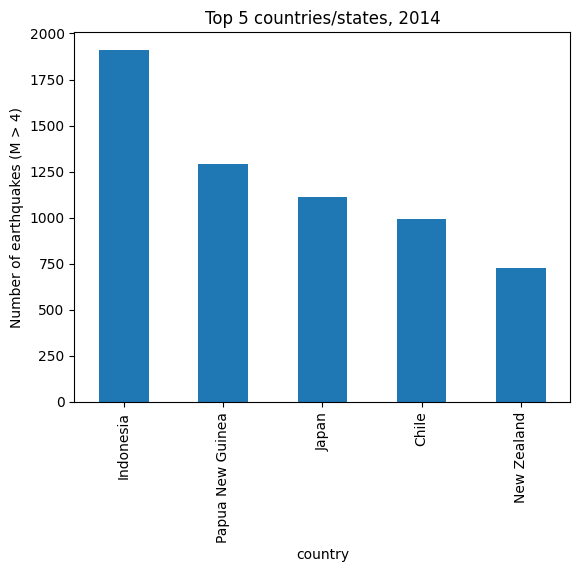

In [31]:
#Q9 second try
# Count the >4 earthquakes, count them per country, then plot the top 5 as a bar chart
num_1 = df_m4["mag"].count()
print("Num 1:", num_1)

num_2 = df_m4["country"].value_counts()
top5 = num_2.head(5).reset_index()
top5.columns = ["country", "earthquake_num"]
print(top5)

top5.plot.bar(x="country", y="earthquake_num", legend=False)
plt.ylabel("Number of earthquakes (M > 4)")
plt.title("Top 5 countries/states, 2014")
plt.show()

✍ ***Q9 REFLECTIVE COMMENT*** ✍

Counting was quick, but the bar chart gave me `KeyError: 'earthquake_num'`. I expected the column to already have the name asked in the exercise, but after `reset_index()` pandas calls it `count`. Once I printed `top5` and saw the real column names, I renamed them myself with `top5.columns = [...]`, and the chart worked.

**Q10) Make a histogram for the distribution of the earthquakes' magnitudes.**

Hint: pandas has a histogram function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html) and
matplotlib has one documented
[at this link](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist.png" alt="A histogram of earthquake magnitude with a dashed grid" width="700">

<em>The distribution of magnitude across the whole catalog.</em>


Then redraw it with a logarithmic scale on the y-axis, which brings the rare large events into
view alongside the many small ones. Hint: here you can find a
[tutorial](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yscale.html) for how to
change an axis scale.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist-log.png" alt="The same histogram of earthquake magnitude with a logarithmic y-axis" width="700">

<em>The same histogram with a logarithmic count axis.</em>


Finally, make one histogram for the filtered dataset and one for the unfiltered dataset, side by
side.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-hist-filtered-unfiltered.png" alt="Two histograms of earthquake magnitude side by side, one for events above magnitude 4 and one for the whole catalog" width="100%">

<em>The filtered and unfiltered magnitude distributions, drawn on their own count axes.</em>

AttributeError: Rectangle.set() got an unexpected keyword argument 'yscale'

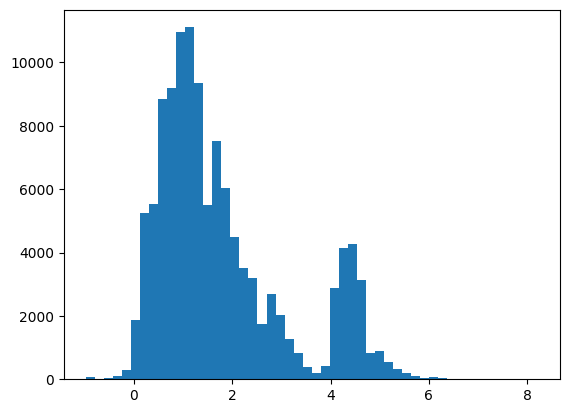

In [33]:
#Q10 first try
# Make the three histograms
plt.hist(df["mag"].dropna(), bins=50, yscale="log")
plt.show()

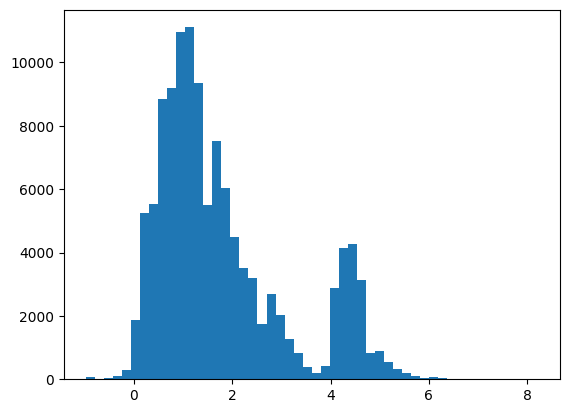

In [34]:
#Q10 second try
# Make the three histograms
plt.hist(df["mag"].dropna(), bins=50)
plt.yscale = "log"
plt.show()

TypeError: 'str' object is not callable

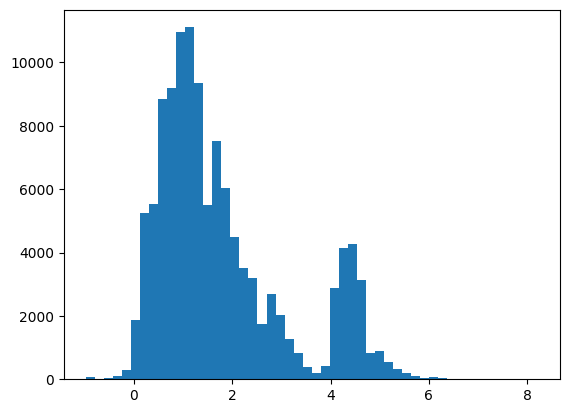

In [35]:
#Q10 third try
# Make the three histograms
plt.hist(df["mag"].dropna(), bins=50)
plt.yscale("log")
plt.show()

✍ ***Q10 REFLECTIVE COMMENT*** ✍

I didn't manage to solve this one. First I tried to put `yscale="log"` directly inside `plt.hist` and got `AttributeError: Rectangle.set() got an unexpected keyword argument 'yscale'`. Then I wrote `plt.yscale = "log"`: no error, but the plot still wasn't logarithmic. On my third try, `plt.yscale("log")` gave me `TypeError: 'str' object is not callable` but I did not know how to fix it.

**Q11) Visualise the locations of earthquakes by making a scatterplot of their latitude and longitude.**

Make a figure with two panels: one for the filtered dataset and one for the unfiltered one, with
the points coloured by magnitude on a shared colour range.

Hint: consider reading the documentation for
[`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) to make
the scatter plot and that of
[`plt.colorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) to
colour the points by magnitude. Pass the same `vmin` and `vmax` to both scatter calls, so that a
colour stands for the same magnitude in both panels.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-quake-scatter.png" alt="Two scatter plots of earthquake longitude against latitude coloured by magnitude, one filtered to magnitude above 4 and one unfiltered" width="100%">

<em>Every event in the catalog placed by longitude and latitude, filtered and unfiltered.</em>

RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

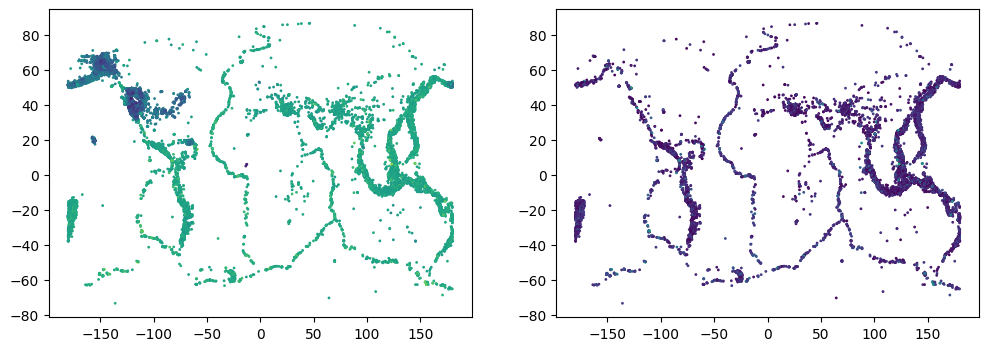

In [36]:
#Q11 first try
# Make the two scatter plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(df["longitude"], df["latitude"], c=df["mag"], s=1)
ax2.scatter(df_m4["longitude"], df_m4["latitude"], c=df_m4["mag"], s=1)
plt.colorbar()
plt.show()

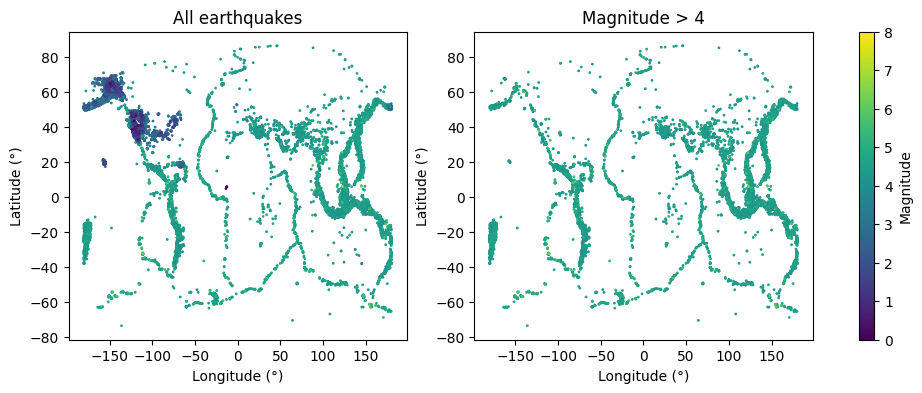

In [37]:
#Q11 second try
# Make the two scatter plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(df["longitude"], df["latitude"], c=df["mag"], s=1, vmin=0, vmax=8)
ax1.set_title("All earthquakes")
sc = ax2.scatter(df_m4["longitude"], df_m4["latitude"], c=df_m4["mag"], s=1, vmin=0, vmax=8)
ax2.set_title("Magnitude > 4")
for ax in (ax1, ax2):
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
fig.colorbar(sc, ax=[ax1, ax2], label="Magnitude")
plt.show()

Do you notice a difference between the filtered and unfiltered datasets?

Response: *Yes. The unfiltered map is full of small earthquakes in the USA, where there are many sensors. The filtered one (M > 4) mostly shows the plate boundaries, like the Pacific Ring of Fire.*

✍ ***Q11 REFLECTIVE COMMENT*** ✍

My first try gave me `RuntimeError: No mappable was found to use for colorbar creation`. Since I drew the points with `ax.scatter`, `plt.colorbar()` didn't know which plot to take the colours from. I fixed it by saving the scatter in a variable (`sc`) and passing it to `fig.colorbar`. I also used the same `vmin` and `vmax` in both plots, so the same colour means the same magnitude.


